Prairie Crop Tracker
Do wet Junes hurt corn yields in Stearns County, Minnesota?

Project Slice
- Location: Stearns County, Minnesota
- Crop: Corn for grain
- Yield measurement: Bushels per acre
- Study period: 2004–2025

Data Sources
1. USDA NASS Quick Stats API: Annual county corn yield estimates.
2. Open-Meteo Historical Weather API: Daily precipitation and
   temperature observations for St. Cloud, Minnesota.

  
ETL Plan:

Extract: Download annual corn yields and daily weather data.
Transform: Clean yield records, aggregate weather by year,
calculate yield trends and yield anomalies.
Load: Save cleaned data to CSV files and a SQLite database.
Analyze: Compare yield anomalies during wet, normal, and dry Junes.

Hypothesis:

I predict that years with unusually wet Junes will have lower
corn yields because wet months cause flooding and
delay planting.

**Step 1**

1.1
Imports libraries. Uses requests to connect to the USDA and Open-Meteo APIs, pandas to Organize, clean, and combine datasets, matplotlib to create the required charts, sqlite3 to store data and run SQL queries, json to save and read raw API responses, datetime to work with dates and years, numpy to calculate trend lines and yield anomalies, os to create folders for project files.

1.2
Creates paths to new folders. Makes 3 new folders: data, raw, and clean. The raw and clean folders are stored into the data folder.

1.3
Defines the start/end year for the time period I am studying. Also defines the State and County.

1.4
Gives the Longitude and Latitude of Stearns County, MN so Colab knows where to look for the data we need.

In [ ]:
# ============================================================
# STEP 1: SETUP
# ============================================================

#1.1 Install/import libraries

import requests
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3
import json
import datetime
import numpy as np
import os

from pathlib import Path

#1.2 Create project folders
Path("data").mkdir(exist_ok=True)
Path("data/raw").mkdir(parents=True, exist_ok=True)
Path("data/clean").mkdir(parents=True, exist_ok=True)

#1.3 Study settings
START_YEAR = 2004
END_YEAR = 2025

STATE = "MN"
COUNTY = "STE​​ARNS"

#1.4 St. Cloud, Minnesota coordinates
LATITUDE = 45.5579
LONGITUDE = -94.163

1.1
Libraries were imported.

1.2
3 new folders were created for the data.

1.3
start/end dates as well as the county I am studying were defined.

1.4
longitude and latitude were defined.

**Step 2**

2.1
Defines the API's URL then gives the nass_params to define parameters of data that I want to extract. We are using Survey data for corn yield in Stearns county, MN from 2004-2025 in JSON format. requests.get then asks the API (the USDA) for these parameters. I then opened the raw data folder and put the data in there with the json.dump command. The code then counts and prints the amount of records retrieved.

2.2
Connects to Open-Meteo API and asks for data with the parameters of where/when we are studying, with the daily max, average, and sum of precipitation for each day. It then saves the info into the data/raw/weather file.

2.3
Prints the total number of records recieved and confirms where the files are saved.

In [ ]:
# ============================================================
# STEP 2: EXTRACT DATA
# ============================================================

# 2.1: Extract USDA corn yield data

# USDA API website
nass_url = "https://quickstats.nass.usda.gov/api/api_GET/"

# Clean county name to remove hidden zero-width spaces if present
CLEAN_COUNTY = COUNTY.replace("\u200b", "")

# Parameters tell USDA which data we want
# PLACE YOUR USDA API KEY IN THE 'key' FIELD BELOW
nass_params = {
    "key": "8541283F-D5A5-315D-9B1A-F498D4D4A6EC",
    "source_desc": "SURVEY",
    "commodity_desc": "CORN",
    "statisticcat_desc": "YIELD",
    "agg_level_desc": "COUNTY",
    "state_alpha": STATE,
    "county_name": CLEAN_COUNTY,
    "year__GE": START_YEAR,
    "year__LE": END_YEAR,
    "format": "JSON"
}

try:
    # Send request to USDA
    nass_response = requests.get(
        nass_url,
        params=nass_params,
        timeout=60
    )

    # Check if request worked
    print("\nUSDA Status Code:", nass_response.status_code)

    nass_response.raise_for_status()

    # Convert response into JSON
    nass_data = nass_response.json()

    # Save original response without modifying its contents
    with open("data/raw/usda_yields_raw.json", "w") as file:
        json.dump(nass_data, file, indent=4)

    # Count USDA records
    yield_records = nass_data.get("data", [])

    print("USDA corn yield records:", len(yield_records))
    print("USDA raw data saved successfully!")

except requests.exceptions.RequestException as error:
    print("USDA API request failed:", error)
    raise

except ValueError as error:
    print("USDA returned invalid JSON:", error)
    raise


# 2.2: Extract historical weather data

# Open-Meteo historical weather API
weather_url = "https://archive-api.open-meteo.com/v1/archive"

# Parameters tell Open-Meteo which weather data we want
weather_params = {
    "latitude": LATITUDE,
    "longitude": LONGITUDE,
    "start_date": f"{START_YEAR}-01-01",
    "end_date": f"{END_YEAR}-12-31",
    "daily": [
        "precipitation_sum",
        "temperature_2m_max",
        "temperature_2m_mean"
    ],
    "timezone": "America/Chicago",
    "precipitation_unit": "inch",
    "temperature_unit": "fahrenheit"
}

try:
    # Send request to Open-Meteo
    weather_response = requests.get(
        weather_url,
        params=weather_params,
        timeout=120
    )

    # Check if request worked
    print("\nWeather Status Code:", weather_response.status_code)

    weather_response.raise_for_status()

    # Convert response into JSON
    weather_data = weather_response.json()

    # Save original response without modifying its contents
    with open("data/raw/weather_raw.json", "w") as file:
        json.dump(weather_data, file, indent=4)

    # Count daily weather records
    weather_records = weather_data["daily"]["time"]

    print("Daily weather records:", len(weather_records))
    print("Weather raw data saved successfully!")

except requests.exceptions.RequestException as error:
    print("Weather API request failed:", error)
    raise

except (ValueError, KeyError) as error:
    print("Weather data error:", error)
    raise


# 2.3: Final extraction summary

print("\n====================================")
print("STEP 2 EXTRACTION COMPLETE!")
print("====================================")

print("USDA records:", len(yield_records) if 'yield_records' in locals() else 0)
print("Weather records:", len(weather_records) if 'weather_records' in locals() else 0)

print("\nFiles saved:")
print("data/raw/usda_yields_raw.json")
print("data/raw/weather_raw.json")


USDA Status Code: 200
USDA corn yield records: 41
USDA raw data saved successfully!

Weather Status Code: 200
Daily weather records: 8036
Weather raw data saved successfully!

STEP 2 EXTRACTION COMPLETE!
USDA records: 41
Weather records: 8036

Files saved:
data/raw/usda_yields_raw.json
data/raw/weather_raw.json


2.1
The USDA status code 200 means the extraction was successful and we have recieved 41 USDA corn yield records

2.2
The data extraction was successful and we have received 8036 weather records.

2.3
We have recieved confirmation on where the data was saved to.

**Step 3**

3.1
uses the with open command to open the weather and USDA data in the raw data folder. It also loads the contents onto google colab.

3.2
converts the raw data into a panda data frame with the pd.DataFrame command. This way Colab is able to work with the data in rows and columns.

3.3
Prints what types of data that were extracted from the API's.

3.4
uses the isnull().sum() to sum up the missing values in each column from the USDA and weather data.

3.5
Uses the if value command to print the values in the USDA yield section to see if they are numbers or text. Then makes sure that the corn and silage is in the same units with the unit_desc. Counts the number of duplicated values with nNumber, and then checks if there are any missing weather values by using the isnull().sum() command.

3.6
Prints the length of weather and USDA yield records that were retrieved.

In [ ]:

# ============================================================
# STEP 3: EXPLORE THE RAW DATA
# ============================================================


# 3.1: Load the original JSON files

with open("data/raw/usda_yields_raw.json", "r") as file:
    nass_data = json.load(file)

with open("data/raw/weather_raw.json", "r") as file:
    weather_data = json.load(file)

print("\nBoth JSON files loaded successfully!")


# 3.2: Convert JSON data into DataFrames

# Convert USDA records into a DataFrame
yield_df_raw = pd.DataFrame(nass_data.get("data", []))

# Convert daily weather records into a DataFrame
weather_df_raw = pd.DataFrame(weather_data["daily"])

# Rename the time column to date
weather_df_raw = weather_df_raw.rename(
    columns={"time": "date"}
)

# Convert dates into actual date values
weather_df_raw["date"] = pd.to_datetime(
    weather_df_raw["date"]
)

print("\n========== DATAFRAME PREVIEWS ==========")

print("\nUSDA DataFrame:")
display(yield_df_raw.head())

print("\nWeather DataFrame:")
display(weather_df_raw.head())

# 3.3: Examine data types

print("\n========== DATA TYPES ==========")

print("\nUSDA data types:")
print(yield_df_raw.dtypes)

print("\nWeather data types:")
print(weather_df_raw.dtypes)


# 3.4: Check missing values

print("\n========== MISSING VALUES ==========")

print("\nUSDA missing values:")
print(yield_df_raw.isnull().sum())

print("\nWeather missing values:")
print(weather_df_raw.isnull().sum())


# 3.5: Identify data-quality problems

print("\n========== DATA QUALITY CHECKS ==========")

# Check yield values stored as text
if "Value" in yield_df_raw.columns:
    print("\nUSDA yield values:")
    print(yield_df_raw["Value"].head(10).tolist())

    print("\nUSDA special yield codes:")
    print(
        yield_df_raw[
            yield_df_raw["Value"].isin(["(D)", "(NA)"])
        ]["Value"].value_counts()
    )

# Check different corn measurements
if "short_desc" in yield_df_raw.columns:
    print("\nUSDA corn measurement types:")
    print(yield_df_raw["short_desc"].value_counts())

if "unit_desc" in yield_df_raw.columns:
    print("\nUSDA measurement units:")
    print(yield_df_raw["unit_desc"].value_counts())

# Check duplicate USDA years
if "year" in yield_df_raw.columns:
    print(
        "\nNumber of duplicate USDA year records:",
        yield_df_raw.duplicated(subset=["year"]).sum()
    )

# Check missing daily weather observations
weather_columns = [
    "precipitation_sum",
    "temperature_2m_max",
    "temperature_2m_mean"
]

print("\nMissing weather observations:")
print(weather_df_raw[weather_columns].isnull().sum())


# 3.6: Final exploration summary

print("\n==========================================")
print("STEP 3 RAW DATA EXPLORATION COMPLETE!")
print("==========================================")

print("USDA records examined:", len(yield_df_raw))
print("Weather records examined:", len(weather_df_raw))
print("Next step: Clean and transform the data.")



Both JSON files loaded successfully!

========== DATAFRAME PREVIEWS ==========

USDA DataFrame:


,begin_code,source_desc,short_desc,statisticcat_desc,domain_desc,watershed_desc,state_name,country_name,watershed_code,class_desc,...,state_alpha,end_code,region_desc,state_fips_code,sector_desc,CV (%),unit_desc,domaincat_desc,Value,year
0,00,SURVEY,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",YIELD,TOTAL,,MINNESOTA,UNITED STATES,00000000,ALL CLASSES,...,MN,00,,27,CROPS,3.5,BU / ACRE,NOT SPECIFIED,175.6,2025
1,00,SURVEY,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",YIELD,TOTAL,,MINNESOTA,UNITED STATES,00000000,ALL CLASSES,...,MN,00,,27,CROPS,2.7,BU / ACRE,NOT SPECIFIED,186.8,2024
2,00,SURVEY,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",YIELD,TOTAL,,MINNESOTA,UNITED STATES,00000000,ALL CLASSES,...,MN,00,,27,CROPS,4.4,BU / ACRE,NOT SPECIFIED,187.3,2023
3,00,SURVEY,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",YIELD,TOTAL,,MINNESOTA,UNITED STATES,00000000,ALL CLASSES,...,MN,00,,27,CROPS,3.4,BU / ACRE,NOT SPECIFIED,185.4,2022
4,00,SURVEY,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",YIELD,TOTAL,,MINNESOTA,UNITED STATES,00000000,ALL CLASSES,...,MN,00,,27,CROPS,6.3,BU / ACRE,NOT SPECIFIED,148.2,2021



Weather DataFrame:


,date,precipitation_sum,temperature_2m_max,temperature_2m_mean
0,2004-01-01,0.000,34.1,23.3
1,2004-01-02,0.039,36.0,26.1
2,2004-01-03,0.000,15.0,8.4
3,2004-01-04,0.008,6.4,1.9
4,2004-01-05,0.000,-1.5,-7.0



========== DATA TYPES ==========

USDA data types:
begin_code               object
source_desc              object
short_desc               object
statisticcat_desc        object
domain_desc              object
watershed_desc           object
state_name               object
country_name             object
watershed_code           object
class_desc               object
county_name              object
freq_desc                object
group_desc               object
util_practice_desc       object
asd_code                 object
county_ansi              object
zip_5                    object
county_code              object
load_time                object
state_ansi               object
week_ending              object
location_desc            object
congr_district_code      object
country_code             object
commodity_desc           object
agg_level_desc           object
prodn_practice_desc      object
asd_desc                 object
reference_period_desc    object
state_alpha         

3.1
USDA and weather data were loaded onto Google Colab.

3.2
raw data was converted to a data frame.

3.3
the types of data that were extracted from the API's were printed.

3.4
the Missing values in the weather and USDA yield columns were counted.

3.5
The types of data retrieved were printed.

3.6
Prints the number of records retrieved were counted and printed.

**Step 4**

4.1
Prints the rows before cleaning then uses na=false to remove the USDA data that has corn not harvested for grain. then uses the na=false command to only keep the BU/Acre measurements and get rid of all data using other measurements.

4.2
Uses the str.replace command to replace commas in numbers to just be blank. Also gets rid of all values that use code instead of real measurements. Then converts the bu/acre into a real numeric value with the pd.to_numeric code. Finally, this section prints the rows without usable values.

4.3
Converts date into numeric with the pd.to_numeric code. Uses drop.na to get rid of data that doesn't have a year.

4.4
Counts the amount of duplicate rows in the year data with the len() code. Then uses grain_df.drop_duplicates to get rid of those rows.

4.5
Uses the pd.to_datetime to convert the weather data into a normal date and time format for colab. Then uses drop.na to drop the data without dates. converts the weather data to a numeric value with pd.to_numeric code. And finally, this step creates a year and month column from the date column.

4.6
Prints the rows before and after cleaning then gives a snapshot of what the data looks like now.

In [ ]:
# ============================================
# STEP 4: CLEAN AND TRANSFORM
# ============================================

# --------------------------------------------
# 4.1: CLEAN USDA CORN YIELD DATA
# --------------------------------------------

print("SECTION 1: CLEAN USDA YIELD DATA")

# Show original number of rows
print("Rows before cleaning:", len(yield_df_raw))

# Make a copy so the original raw data stays unchanged
grain_df = yield_df_raw.copy()

# Keep only corn harvested for grain
# This removes corn silage records
grain_df = grain_df[
    grain_df["short_desc"].str.contains(
        "CORN, GRAIN",
        case=False,
        na=False
    )
]

# Keep only bushels per acre measurements
grain_df = grain_df[
    grain_df["unit_desc"].str.contains(
        "BU / ACRE",
        case=False,
        na=False
    )
]

print("Rows after keeping corn grain:", len(grain_df))


# --------------------------------------------
# 4.2: CLEAN USDA YIELD VALUES
# --------------------------------------------

print("\nSECTION 2: CLEAN YIELD VALUES")

# Preserve the original values for reference
grain_df["original_value"] = grain_df["Value"].astype(str)

# Remove commas from numbers such as 1,234
grain_df["Value"] = (
    grain_df["Value"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.strip()
)

# Convert USDA special codes into missing values
# (D) = Withheld to protect individual farms
# (NA) = Not available
# Other nonnumeric codes are also treated as missing

special_codes = ["(D)", "(NA)", "(Z)", "(X)", "(S)"]

grain_df.loc[
    grain_df["Value"].str.upper().isin(special_codes),
    "Value"
] = np.nan

# Convert yield values into numbers
grain_df["yield_bu_acre"] = pd.to_numeric(
    grain_df["Value"],
    errors="coerce"
)

print("Missing or nonnumeric yields:",
      grain_df["yield_bu_acre"].isna().sum())

# Remove rows without usable numerical yields
grain_df = grain_df.dropna(
    subset=["yield_bu_acre"]
).copy()

print("Rows after cleaning yield values:", len(grain_df))


# --------------------------------------------
# 4.3: FIX DATA TYPES
# --------------------------------------------

print("\nSECTION 3: FIX DATA TYPES")

# Convert year into a numeric value
grain_df["year"] = pd.to_numeric(
    grain_df["year"],
    errors="coerce"
)

# Remove records with missing or invalid years
grain_df = grain_df.dropna(
    subset=["year"]
).copy()

# Convert year into an integer
grain_df["year"] = grain_df["year"].astype(int)

print("Year data type:", grain_df["year"].dtype)
print("Yield data type:", grain_df["yield_bu_acre"].dtype)


# --------------------------------------------
# 4.4: CHECK AND REMOVE DUPLICATES
# --------------------------------------------

print("\nSECTION 4: CHECK DUPLICATES")

print("Rows before duplicate check:", len(grain_df))

# Check for duplicate records for the same year
duplicate_rows = grain_df[
    grain_df.duplicated(
        subset=["year"],
        keep=False
    )
]

print("Duplicate year records found:",
      len(duplicate_rows))

if len(duplicate_rows) > 0:
    print("\nDuplicate records to review:")
    display(
        duplicate_rows[
            ["year", "Value", "short_desc", "unit_desc"]
        ].sort_values("year")
    )

    # Remove only exact duplicate records.
    # Do not automatically discard different yield
    # estimates for the same year.
    grain_df = grain_df.drop_duplicates()

print("Rows after exact duplicate removal:", len(grain_df))



# --------------------------------------------
# 4.5: CLEAN WEATHER DATA
# --------------------------------------------

print("\nSECTION 5: CLEAN WEATHER DATA")

print("Weather rows before cleaning:", len(weather_df_raw))

# Make a copy of the original weather data
weather_clean = weather_df_raw.copy()

# Convert dates into datetime format (using 'date' column renamed in step 3)
weather_clean["date"] = pd.to_datetime(
    weather_clean["date"],
    errors="coerce"
)

# Remove records without valid dates
weather_clean = weather_clean.dropna(
    subset=["date"]
).copy()

# Convert weather measurements into numbers
weather_columns = [
    "precipitation_sum",
    "temperature_2m_max",
    "temperature_2m_mean"
]

for column in weather_columns:
    weather_clean[column] = pd.to_numeric(
        weather_clean[column],
        errors="coerce"
    )


# Create year and month columns (using 'date' column)
weather_clean["year"] = weather_clean["date"].dt.year
weather_clean["month"] = weather_clean["date"].dt.month

print("Weather rows after cleaning:", len(weather_clean))

print("\nWeather missing values:")
print(weather_clean[weather_columns].isna().sum())


# --------------------------------------------
# 4.6: FINAL CLEANING SUMMARY
# --------------------------------------------

print("\nSECTION 6: FINAL CLEANING SUMMARY")

print("USDA yield rows remaining:", len(grain_df))
print("Weather rows remaining:", len(weather_clean))

print("\nClean USDA yield data:")
display(
    grain_df[
        ["year", "yield_bu_acre", "short_desc", "unit_desc"]
    ].head()
)

print("\nClean weather data:")
display(weather_clean.head())

print("\nSTEP 4 CLEANING COMPLETE!")

SECTION 1: CLEAN USDA YIELD DATA
Rows before cleaning: 41
Rows after keeping corn grain: 22

SECTION 2: CLEAN YIELD VALUES
Missing or nonnumeric yields: 0
Rows after cleaning yield values: 22

SECTION 3: FIX DATA TYPES
Year data type: int64
Yield data type: float64

SECTION 4: CHECK DUPLICATES
Rows before duplicate check: 22
Duplicate year records found: 0
Rows after exact duplicate removal: 22

SECTION 5: CLEAN WEATHER DATA
Weather rows before cleaning: 8036
Weather rows after cleaning: 8036

Weather missing values:
precipitation_sum      0
temperature_2m_max     0
temperature_2m_mean    0
dtype: int64

SECTION 6: FINAL CLEANING SUMMARY
USDA yield rows remaining: 22
Weather rows remaining: 8036

Clean USDA yield data:


,year,yield_bu_acre,short_desc,unit_desc
0,2025,175.6,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",BU / ACRE
1,2024,186.8,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",BU / ACRE
2,2023,187.3,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",BU / ACRE
3,2022,185.4,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",BU / ACRE
4,2021,148.2,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",BU / ACRE



Clean weather data:


,date,precipitation_sum,temperature_2m_max,temperature_2m_mean,year,month
0,2004-01-01,0.000,34.1,23.3,2004,1
1,2004-01-02,0.039,36.0,26.1,2004,1
2,2004-01-03,0.000,15.0,8.4,2004,1
3,2004-01-04,0.008,6.4,1.9,2004,1
4,2004-01-05,0.000,-1.5,-7.0,2004,1



STEP 4 CLEANING COMPLETE!


4.1
The rows before and after getting rid of values that represent corn not harvested for grain were printed.

4.2
The number of rows with missing data and number of rows left were printed.

4.3
data types were printed.

4.4
The duplicate rows for year were counted and discarded (there were none).

4.5
Rows before and after cleaning the weather data were printed.

4.6
There is a snapshot of what the data table looks like now after cleaning displayed.

**Step 5**

5.1
Copies year and yield for bushels/acre columns with .copy(). Then makes sure that year is an integer with .astype(int). Then uses sort_values() to sort the data by year.

5.2
Copies the June weather into a new folder named weather_clean. Uses the group.by() to group the data by year and the .agg to add up all the june data from each day into the june_summary. Then converts the june_summary into fahrenheit from celsius.

5.3
Adds up the aggregate rainfall each year for months of May through September with the .groupby and the .agg.

5.4
uses the .merge command to merge the weather and yield data together into one table.

5.5
Orders the combined data by year with indicator=true and gets rid of data for values that don't have a year.

5.6
Uses np.polyfit to find a line of best fit for the trend in the data.

5.7
Finds yield anomaly by subtracting the expected yield from the actual yield and displays the results with the display() code.

5.8
defines dry_cutoff and wet_cutoff variables as the quantile 1 and 3 for the month of June. Then displays what a dry june and wet june would look like.

5.9
displays the final dataset.

In [ ]:

# ============================================
# STEP 5: COMBINE AND DERIVE
# ============================================


# --------------------------------------------
# 5.1: PREPARE USDA YIELD DATA
# --------------------------------------------

print("SECTION 1: PREPARE USDA YIELD DATA")

# Select the columns needed for the project
annual_yield = grain_df[
    ["year", "yield_bu_acre"]
].copy()

# Make sure year is an integer
annual_yield["year"] = annual_yield["year"].astype(int)

# Sort the data by year
annual_yield = annual_yield.sort_values("year")

print("USDA yield records:", len(annual_yield))
display(annual_yield.head())


# --------------------------------------------
# 5.2: AGGREGATE JUNE WEATHER
# --------------------------------------------

print("\nSECTION 2: AGGREGATE JUNE WEATHER")

# Select June weather observations
june_weather = weather_clean[
    weather_clean["month"] == 6
].copy()

# Group daily observations into yearly summaries
june_summary = (
    june_weather.groupby("year")
    .agg(
        june_rain_inches=(
            "precipitation_sum",
            lambda x: x.sum(min_count=1)
        ),
        june_mean_temp_c=(
            "temperature_2m_mean",
            "mean"
        ),
        june_mean_max_temp_c=(
            "temperature_2m_max",
            "mean"
        ),
        june_days_observed=(
            "date",
            "count"
        )
    )
    .reset_index()
)

# Convert Celsius to Fahrenheit
june_summary["june_mean_temp_f"] = (
    june_summary["june_mean_temp_c"] * 9/5 + 32
)

print("June weather records:", len(june_summary))
display(june_summary.head())


# --------------------------------------------
# 5.3: CALCULATE MAY-SEPTEMBER RAINFALL
# --------------------------------------------

print("\nSECTION 3: GROWING SEASON RAINFALL")

# Select May through September
growing_season = weather_clean[
    weather_clean["month"].between(5, 9)
].copy()

# Calculate total growing-season rainfall
growing_summary = (
    growing_season.groupby("year")
    .agg(
        may_sep_rain_inches=(
            "precipitation_sum",
            lambda x: x.sum(min_count=1)
        )
    )
    .reset_index()
)

print("Growing season records:", len(growing_summary))
display(growing_summary.head())


# --------------------------------------------
# 5.4: COMBINE WEATHER SUMMARIES
# --------------------------------------------

print("\nSECTION 4: COMBINE WEATHER SUMMARIES")

# Join June weather with growing-season rainfall
annual_weather = june_summary.merge(
    growing_summary,
    on="year",
    how="outer"
)

annual_weather = annual_weather.sort_values("year")

print("Annual weather records:", len(annual_weather))
display(annual_weather.head())


# --------------------------------------------
# 5.5: JOIN USDA AND WEATHER DATA
# --------------------------------------------

print("\nSECTION 5: JOIN BOTH DATA SOURCES")

# Match the datasets using the year column
combined_df = annual_yield.merge(
    annual_weather,
    on="year",
    how="left",
    indicator=True
)

# Display the results of the join
print("Total combined records:", len(combined_df))

print("\nJoin results:")
print(combined_df["_merge"].value_counts())

# Identify years without matching weather
unmatched = combined_df[
    combined_df["_merge"] != "both"
]

print("\nYears without matching weather:")
print(unmatched["year"].tolist())

# Remove the merge indicator from final dataset
combined_df = combined_df.drop(columns=["_merge"])

display(combined_df.head())


# --------------------------------------------
# 5.6: CALCULATE LONG-TERM YIELD TREND
# --------------------------------------------

print("\nSECTION 6: CALCULATE YIELD TREND")

# Use years with actual numerical yields
valid_yields = combined_df.dropna(
    subset=["yield_bu_acre"]
).copy()

# Fit a straight trend line
slope, intercept = np.polyfit(
    valid_yields["year"],
    valid_yields["yield_bu_acre"],
    1
)

# Calculate expected yield based on the trend
combined_df["trend_yield"] = (
    slope * combined_df["year"] + intercept
)

print(
    "Annual yield trend:",
    round(slope, 3),
    "bushels per acre per year"
)


# --------------------------------------------
# 5.7: CALCULATE YIELD ANOMALIES
# --------------------------------------------

print("\nSECTION 7: CALCULATE YIELD ANOMALIES")

# Actual yield minus expected trend yield
combined_df["yield_anomaly"] = (
    combined_df["yield_bu_acre"]
    - combined_df["trend_yield"]
)

print("Yield anomaly calculations complete.")

display(
    combined_df[
        [
            "year",
            "yield_bu_acre",
            "trend_yield",
            "yield_anomaly"
        ]
    ].head(10)
)


# --------------------------------------------
# 5.8: CLASSIFY JUNE RAINFALL
# --------------------------------------------

print("\nSECTION 8: CLASSIFY JUNE RAINFALL")

# Calculate rainfall quartiles
valid_rain = combined_df[
    "june_rain_inches"
].dropna()

dry_cutoff = valid_rain.quantile(0.25)
wet_cutoff = valid_rain.quantile(0.75)

print("Dry June cutoff:", round(dry_cutoff, 2), "inches")
print("Wet June cutoff:", round(wet_cutoff, 2), "inches")

# Create wet, normal and dry categories
def classify_june(rain):
    if pd.isna(rain):
        return np.nan
    elif rain <= dry_cutoff:
        return "Dry"
    elif rain >= wet_cutoff:
        return "Wet"
    else:
        return "Normal"

combined_df["june_category"] = (
    combined_df["june_rain_inches"].apply(classify_june)
)

print("\nJune rainfall category counts:")
print(combined_df["june_category"].value_counts())


# --------------------------------------------
# 5.9: FINAL COMBINED DATASET
# --------------------------------------------

print("\nSECTION 9: FINAL COMBINED DATASET")

# Sort records by year
combined_df = combined_df.sort_values("year").reset_index(drop=True)

# Display final columns
print("Final dataset rows:", len(combined_df))

print("\nFinal dataset columns:")
print(combined_df.columns.tolist())

print("\nFinal combined dataset:")
display(combined_df.head(15))

print("\nSTEP 5 COMPLETE!")

SECTION 1: PREPARE USDA YIELD DATA
USDA yield records: 22


,year,yield_bu_acre
21,2004,144.0
20,2005,144.0
19,2006,115.0
18,2007,96.0
17,2008,149.0



SECTION 2: AGGREGATE JUNE WEATHER
June weather records: 22


,year,june_rain_inches,june_mean_temp_c,june_mean_max_temp_c,june_days_observed,june_mean_temp_f
0,2004,4.482,62.493333,70.360000,30,144.488
1,2005,4.818,69.863333,77.846667,30,157.754
2,2006,2.130,68.610000,77.423333,30,155.498
3,2007,2.013,70.253333,79.176667,30,158.456
4,2008,5.485,64.746667,73.010000,30,148.544



SECTION 3: GROWING SEASON RAINFALL
Growing season records: 22


,year,may_sep_rain_inches
0,2004,21.146
1,2005,16.055
2,2006,14.085
3,2007,18.005
4,2008,17.793


... (5 outputs left out)

,year,yield_bu_acre,trend_yield,yield_anomaly
0,2004,144.0,130.593281,13.406719
1,2005,144.0,133.347600,10.652400
2,2006,115.0,136.101920,-21.101920
3,2007,96.0,138.856239,-42.856239
4,2008,149.0,141.610559,7.389441
5,2009,167.0,144.364879,22.635121
6,2010,164.9,147.119198,17.780802
7,2011,136.4,149.873518,-13.473518
8,2012,166.6,152.627837,13.972163
9,2013,133.5,155.382157,-21.882157



SECTION 8: CLASSIFY JUNE RAINFALL
Dry June cutoff: 2.71 inches
Wet June cutoff: 5.22 inches

June rainfall category counts:
june_category
Normal    10
Dry        6
Wet        6
Name: count, dtype: int64

SECTION 9: FINAL COMBINED DATASET
Final dataset rows: 22

Final dataset columns:
['year', 'yield_bu_acre', 'june_rain_inches', 'june_mean_temp_c', 'june_mean_max_temp_c', 'june_days_observed', 'june_mean_temp_f', 'may_sep_rain_inches', 'trend_yield', 'yield_anomaly', 'june_category']

Final combined dataset:


,year,yield_bu_acre,june_rain_inches,june_mean_temp_c,june_mean_max_temp_c,june_days_observed,june_mean_temp_f,may_sep_rain_inches,trend_yield,yield_anomaly,june_category
0,2004,144.0,4.482,62.493333,70.360000,30,144.488,21.146,130.593281,13.406719,Normal
1,2005,144.0,4.818,69.863333,77.846667,30,157.754,16.055,133.347600,10.652400,Normal
2,2006,115.0,2.130,68.610000,77.423333,30,155.498,14.085,136.101920,-21.101920,Dry
3,2007,96.0,2.013,70.253333,79.176667,30,158.456,18.005,138.856239,-42.856239,Dry
4,2008,149.0,5.485,64.746667,73.010000,30,148.544,17.793,141.610559,7.389441,Wet
5,2009,167.0,3.339,65.370000,73.743333,30,149.666,12.841,144.364879,22.635121,Normal
6,2010,164.9,7.008,66.560000,74.036667,30,151.808,27.785,147.119198,17.780802,Wet
7,2011,136.4,3.894,66.030000,74.266667,30,150.854,14.318,149.873518,-13.473518,Normal
8,2012,166.6,4.516,69.373333,78.303333,30,156.872,17.507,152.627837,13.972163,Normal
9,2013,133.5,4.058,65.530000,73.210000,30,149.954,17.362,155.382157,-21.882157,Normal



STEP 5 COMPLETE!


5.1
copies of year and yield data are made.

5.2
new folder called weather_clean is created.

5.3
Aggregate rainfall for the months of May-September found.

5.4
data is combined.

5.5
data is ordered by year.

5.6
line of best fit is found.

5.7
Yield anomalies are identified.

5.8
Dry and wet junes are defined.

5.9 displays the final dataset.

**Step 6**

6.1
Uses .to_csv to save the data tables to csv files so it can be opened by SQLite.

6.2
SQLite database is created with sqlite3.connect().

6.3
Uses .to_sql to transfer the data to SQLite.

6.4
Compares rainfall in June and yield anomalies for dry, wet, or average rainfall years.

6.5
closes connection to SQLite with conn.close().

In [ ]:
# STEP 6: SAVE CLEAN DATA TO CSV AND SQLITE


# 6.1 Save the three tables as CSV files
grain_df.to_csv(
    "data/clean/corn_yields.csv", index=False
)

weather_clean.to_csv(
    "data/clean/annual_weather.csv", index=False
)

combined_df.to_csv(
    "data/clean/crop_weather_analysis.csv", index=False
)

# 6.2 Create a SQLite database
conn = sqlite3.connect(
    "data/clean/prairie_crop_tracker.db"
)

# 6.3 Load the tables into SQLite
grain_df.to_sql(
    "corn_yields", conn, if_exists="replace", index=False
)

weather_clean.to_sql(
    "annual_weather", conn, if_exists="replace", index=False
)

combined_df.to_sql(
    "crop_weather_analysis", conn, if_exists="replace", index=False
)


# 6.4 SQL QUERY 1: Compare rainfall groups
query1 = """
SELECT
    june_category AS rain_group,
    COUNT(*) AS number_of_years,
    ROUND(AVG(june_rain_inches), 2) AS avg_june_rain_inches,
    ROUND(AVG(yield_anomaly), 2) AS avg_yield_anomaly
FROM crop_weather_analysis
GROUP BY june_category
ORDER BY
    CASE june_category
        WHEN 'Dry' THEN 1
        WHEN 'Normal' THEN 2
        WHEN 'Wet' THEN 3
    END;
"""

result1 = pd.read_sql_query(query1, conn)

print("\nSQL QUERY 1: RAINFALL AND YIELD COMPARISON")
display(result1)


# 6.5 Close database connection
conn.close()

print("\nAll CSV files and SQLite database saved successfully!")


SQL QUERY 1: RAINFALL AND YIELD COMPARISON


,rain_group,number_of_years,avg_june_rain_inches,avg_yield_anomaly
0,Dry,6,1.92,-13.00
1,Normal,10,4.05,7.44
2,Wet,6,6.52,0.61



DATABASE TABLES


,name
0,corn_yields
1,annual_weather
2,crop_weather_analysis



All CSV files and SQLite database saved successfully!


6.1
data is converted to csv files.

6.2
SQLite database is created.

6.3
data is tranferred to SQLite.

6.4
table made for yield anomalies by wet, normal or dry years.

6.5
Connection to SQLite is closed.

**Step 7**

7.1
scatter plot for corn yields created with plt.scatter, along with the long term trend line with plt.plot.

7.2
Bar chart created for rainfall by year with plt.bar and classification lines added with .axhline().

7.3
Scatterplot for rainfall vs. yield anomaly created using plt.scatter, along with classification lines with .axvline().

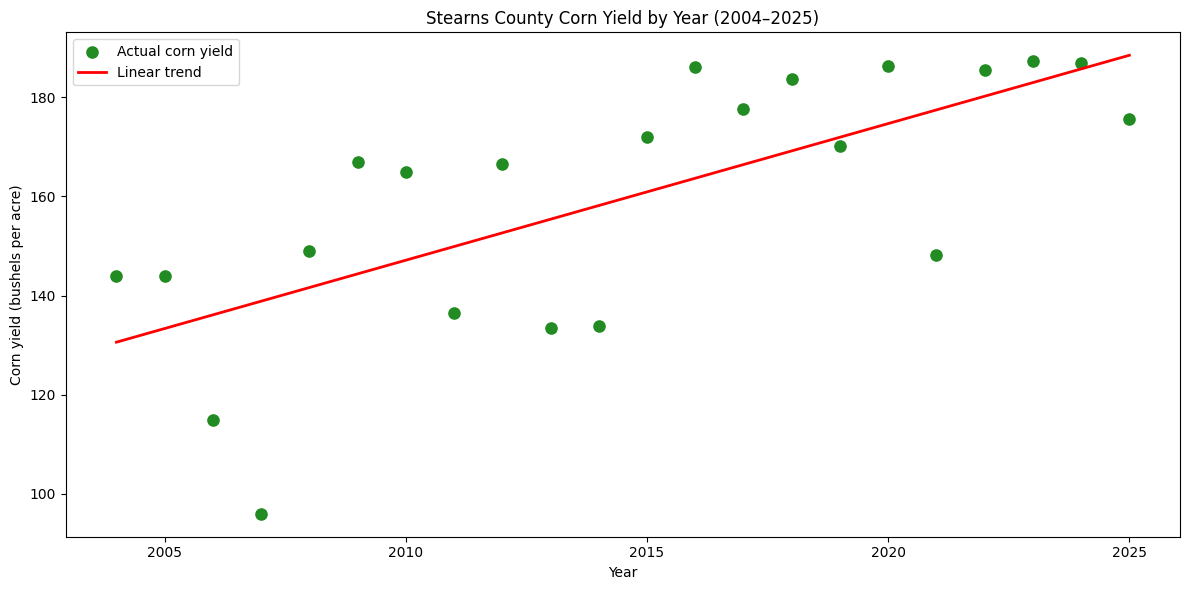

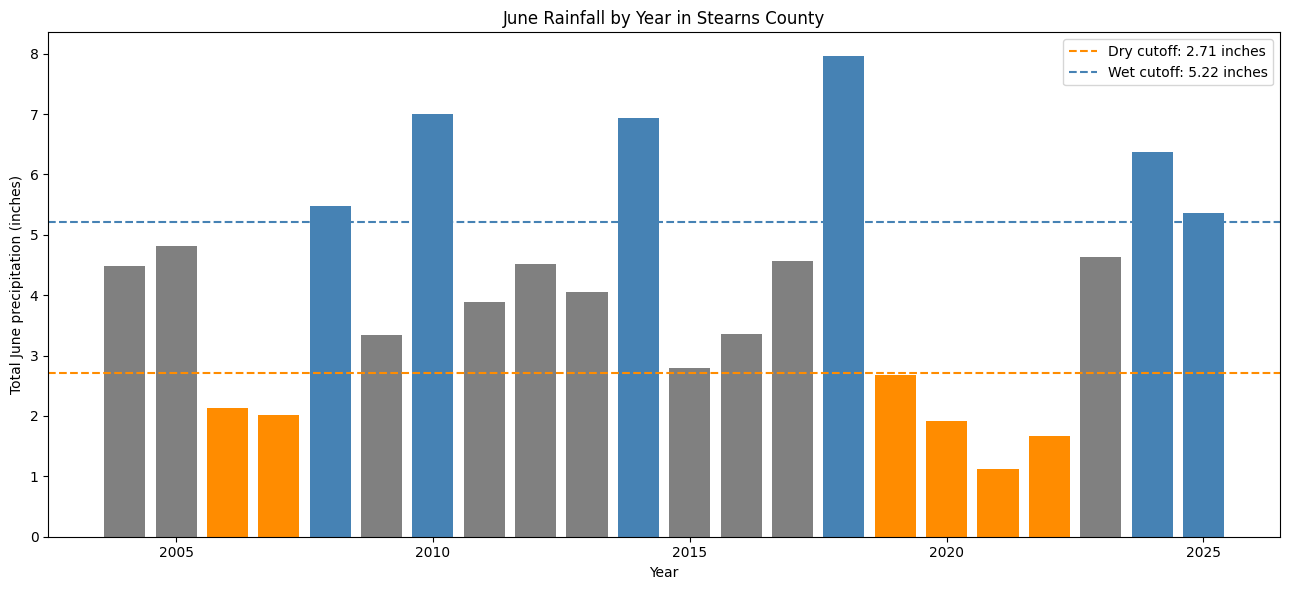

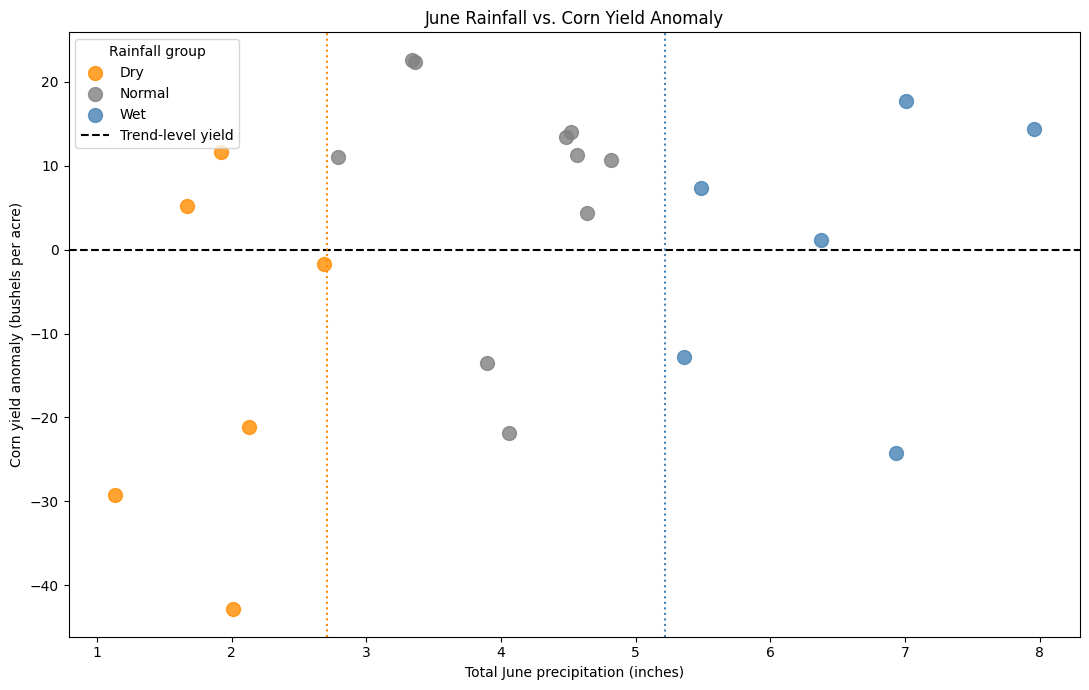

In [ ]:
# STEP 7


# 7.1: CORN YIELD AND TREND LINE

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

# Plot actual corn yields
plt.scatter(
    combined_df["year"],
    combined_df["yield_bu_acre"],
    color="forestgreen",
    s=65,
    label="Actual corn yield"
)

# Plot long-term trend
plt.plot(
    combined_df["year"],
    combined_df["trend_yield"],
    color="red",
    linewidth=2,
    label="Linear trend"
)

# Add chart labels
plt.title(
    "Stearns County Corn Yield by Year (2004–2025)"
)

plt.xlabel("Year")
plt.ylabel("Corn yield (bushels per acre)")

plt.legend()
plt.tight_layout()
plt.show()

# 7.2 JUNE RAINFALL BY YEAR

plt.figure(figsize=(13, 6))

# Assign a different color to each rainfall group
colors = {
    "Dry": "darkorange",
    "Normal": "gray",
    "Wet": "steelblue"
}

# Create the rainfall bar chart
plt.bar(
    combined_df["year"],
    combined_df["june_rain_inches"],
    color=combined_df["june_category"].map(colors)
)

# Add rainfall classification thresholds
plt.axhline(
    dry_cutoff,
    color="darkorange",
    linestyle="--",
    label=f"Dry cutoff: {dry_cutoff:.2f} inches"
)

plt.axhline(
    wet_cutoff,
    color="steelblue",
    linestyle="--",
    label=f"Wet cutoff: {wet_cutoff:.2f} inches"
)

# Add labels
plt.title("June Rainfall by Year in Stearns County")

plt.xlabel("Year")
plt.ylabel("Total June precipitation (inches)")

plt.legend()
plt.tight_layout()
plt.show()


#7.3 RAINFALL VS. YIELD ANOMALY

plt.figure(figsize=(11, 7))

# Create scatter plot
for group in ["Dry", "Normal", "Wet"]:

    subset = combined_df[combined_df["june_category"] == group]

    plt.scatter(
        subset["june_rain_inches"],
        subset["yield_anomaly"],
        color=colors[group],
        label=group,
        s=100,
        alpha=0.8
    )

# Add horizontal reference line at zero
plt.axhline(
    0,
    color="black",
    linestyle="--",
    label="Trend-level yield"
)

# Add rainfall classification thresholds
plt.axvline(
    dry_cutoff,
    color="darkorange",
    linestyle=":"
)

plt.axvline(
    wet_cutoff,
    color="steelblue",
    linestyle=":"
)

# Add chart labels
plt.title(
    "June Rainfall vs. Corn Yield Anomaly"
)

plt.xlabel("Total June precipitation (inches)")
plt.ylabel("Corn yield anomaly (bushels per acre)")

plt.legend(title="Rainfall group")
plt.tight_layout()
plt.show()

7.1
scatter plot for corn yields created.

7.2
Bar chart created for rainfall by year.

7.3
Scatterplot for rainfall vs. yield anomaly created.

**Step 8**

  This project was supposed to answer wether wet or dry Junes are associated with lower crop yields in Stearns county, MN. In graph one, the average yield per year is plotted in a scatter plot and then used to find a line of best fit so we can predict what yield of corn to expect in future yields. We can then use this line to find the years that had anomalies in their corn yields so we can pinpoint which years to look at. Graph 2 then plots the precipitation per year, with yellow being a dry June, grey being an average June, and blue being a wet June. We can then combine the data from these 2 graphs and create graph 3: the rainfall vs. anomaly graph. From this graph, we can see what types of Junes had higher or lower corn yields with the black dashed line representing our expected yield for that year. From this graph, we can see most data points from dry years are far below the expected, while average rainfall years are mostly above, and wet years seem to have a wide spread. From this data, we can see that lower precipitation definitely lowers corn yields, average precipitation typically has higher corn yields, and higher precipitation has wide scattering of corn yields.


  Some limitations to this project includes the lack of data for the high precipitation months, which makes it hard to tell wether wet months have a positive or negative impact on corn yields. Correlation does not neccessarily prove causation either, so we cannot be sure that dry months are the ONLY thing negatively impacting the corn yields.


  This project uses data from Open-Meteo and USDA NASS.